# Phương pháp 3 (bản ngắn) — Huber + Laplacian, giải bằng IRLS

Cùng code và kết quả với `method_3.ipynb`, bỏ phần từ vựng, dẫn xuất IRLS chi tiết và hình minh hoạ loss;
xem bản đầy đủ cho các phần đó.

Bản đồ:
1. Nạp dữ liệu, khối code chung của nhóm, các hàm đánh giá.
2. Giả thiết, loss, IRLS, chọn tham số (tóm tắt); code và các hàm cho nhóm.
3. Kết quả cuối trên dữ liệu thật, `results/method_3/xhat_3.npy`, hình trong `figures/method_3/`.
4. Dòng kết quả cho bảng so sánh.
5. Thuyết minh Mục VI.

Phụ lục: A. `cv_score`; B. dữ liệu giả lập; C. so sánh với Tikhonov trên 100 đồ thị; D. kiểm tra IRLS.

## 1. Dữ liệu và code dùng chung

In [1]:
# ---- Mục III/IV của đề: nạp G, y, positions --------------------------------
# GHI CHÚ: thay MSSV đại diện bằng MSSV THẬT của nhóm (dùng cùng MSSV với notebook
# chung của nhóm), nếu không sẽ ra một đồ thị khác.
import hashlib, json
from pathlib import Path
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Thư mục gốc = thư mục chứa public_cases.json (notebook chạy được từ mọi thư mục con).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "public_cases.json").exists())
FIG_DIR = ROOT / "figures" / "method_3"        # hình của phương pháp này
RES_DIR = ROOT / "results" / "method_3"        # xhat_3.npy
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

MSSV_DAI_DIEN = "20260001"          # <-- đổi thành MSSV đại diện thật của nhóm

def assign_mssv_to_case(student_id, cases):
    # Đúng quy tắc ánh xạ MSSV -> bộ đề của notebook đề bài.
    sid = str(student_id).strip()
    if sid in cases:
        return sid
    case_ids = sorted(cases, key=lambda x: (0, int(x)) if x.isdecimal() else (1, x))
    k = len(case_ids)
    if sid.isdecimal():
        index = int(sid) % k
    else:
        index = int.from_bytes(hashlib.sha256(sid.encode("utf-8")).digest(), "big") % k
    return case_ids[index]

def get_problem(student_id, file_path=ROOT / "public_cases.json"):
    db = json.loads(Path(file_path).read_text(encoding="utf-8"))
    case = db["cases"][assign_mssv_to_case(student_id, db["cases"])]
    G = nx.Graph()
    for i, xy in enumerate(case["positions"]):
        G.add_node(i, pos=tuple(map(float, xy)))
    for u, v, w in case["edges"]:
        G.add_edge(int(u), int(v), weight=float(w))
    y = np.asarray(case["y"], dtype=float)
    assert nx.is_connected(G) and len(y) == G.number_of_nodes()
    return G, y

G, y = get_problem(MSSV_DAI_DIEN)
positions = nx.get_node_attributes(G, "pos")
n = len(y)
print("n nodes =", n, "| n edges =", G.number_of_edges())
print("std(y) = %.4f | range = %.2f .. %.2f" % (np.std(y), y.min(), y.max()))

n nodes = 32 | n edges = 80
std(y) = 1.4070 | range = 16.58 .. 21.67


In [2]:
# ---- Khối "hợp đồng chung" của nhóm ----------------------------------------
# L = Laplacian có trọng số = D - W.  Với mọi tín hiệu x:
#     x^T L x = sum_{(i,j)} w_ij (x_i - x_j)^2
# tức là x^T L x NHỎ khi các đỉnh gần nhau có giá trị giống nhau (tín hiệu "trơn").
n = len(y)
L = nx.laplacian_matrix(G, nodelist=range(n), weight="weight").toarray()

# (a) Dữ liệu giả lập: biết x thật, dùng để đo RMSE.
def make_synthetic(G, y, seed):
    rng = np.random.default_rng(seed)
    lam, U = np.linalg.eigh(L)
    # x = tổ hợp ngẫu nhiên của 5 vector riêng tần số thấp nhất (tín hiệu trơn)
    x = U[:, :5] @ (rng.normal(size=5) / (1 + lam[:5]))
    # đổi thang để x có cùng trung vị / độ lệch chuẩn với y thật
    x = np.median(y) + np.std(y) * x / np.std(x)
    sigma = 0.1 * np.std(y)
    y_syn = x + rng.normal(0, sigma, n)               # nhiễu Gauss
    idx = rng.choice(n, 3, replace=False)             # 3 outlier
    y_syn[idx] += rng.choice([-1, 1], 3) * rng.uniform(4, 8, 3) * sigma
    return x, y_syn

def rmse(a, b): return np.sqrt(np.mean((a - b) ** 2))

# (b) Chọn tham số trên dữ liệu THẬT: che 1/5 số đỉnh rồi dự đoán lại.
def cv_score(solve, y, params, k=5, seed=0):
    folds = np.random.default_rng(seed).permutation(n) % k
    err = []
    for f in range(k):
        mask = folds != f                              # True = được quan sát
        x = solve(G, y, mask=mask, **params)
        err.append(np.abs(x[~mask] - y[~mask]))
    return np.median(np.concatenate(err))              # median => không bị outlier kéo lệch

In [3]:
# ---- Các hàm đánh giá dùng ở mục 4 và các phụ lục ---------------------------
def cv_mean(params, seeds=range(5)):
    # cv_score trung bình trên 5 cách chia — quy ước của nhóm (thấp hơn = tốt hơn).
    return np.mean([cv_score(solve_huber, y, params, seed=sd) for sd in seeds])

def cv_mean20(params, seeds=range(20)):
    # Như trên nhưng 20 cách chia: dùng khi CẦN SO SÁNH các tham số gần nhau, vì
    # với 32 đỉnh một cách chia duy nhất cho cv_score rất nhiễu (xem Phụ lục A).
    return np.mean([cv_score(solve_huber, y, params, seed=sd) for sd in seeds])

def synth_rmse(params, seeds=range(20)):
    # RMSE so với x THẬT trên dữ liệu giả lập, một giá trị mỗi seed (0-19, theo quy ước nhóm).
    out = []
    for sd in seeds:
        x_true, y_syn = make_synthetic(G, y, sd)
        out.append(rmse(solve_huber(G, y_syn, **params), x_true))
    return np.array(out)

## 2. Phương pháp (tóm tắt)

**Giả thiết.** Tín hiệu thật `x` trơn trên đồ thị; quan sát `y = x + ε + o` với `ε` là nhiễu nhỏ (chủ yếu
Gauss) ở mọi đỉnh và `o` là outlier lớn ở một vài đỉnh. Trọng số cạnh là độ tương tự giữa cảm biến. Khác
phương pháp 1, nhiễu có đuôi nặng nên phần khớp dữ liệu phải bền vững.

**Hàm mục tiêu.**

$$
\min_x \; \sum_i \rho_\delta(x_i-y_i) + \lambda\, x^\top L x,
\qquad
\rho_\delta(r)=
\begin{cases}
\tfrac12 r^2, & |r|\le\delta,\\
\delta|r|-\tfrac12\delta^2, & |r|>\delta.
\end{cases}
$$

- `ρ_δ` bậc hai khi `|r| ≤ δ` (hiệu quả với nhiễu Gauss) và tuyến tính khi `|r| > δ` (lực kéo bị chặn ở `δ`,
  nên outlier không kéo lệch nghiệm như bình phương).
- `λxᵀLx = λΣ w_ij(x_i−x_j)²` làm trơn tín hiệu; `λ > 0` bảo đảm nghiệm duy nhất.
- `δ → ∞` cho Tikhonov (phương pháp 1); `δ → 0` tiến tới L1/LAD (phương pháp 4).

**IRLS.** Điều kiện tối ưu `ψ_δ(r_i) + 2λ(Lx)_i = 0`; với `w_i = min(1, δ/|r_i|)` thì `ψ_δ(r_i) = w_i r_i`, nên
`(W + 2λL)x = Wy`, `W = diag(w_i)`. Lặp `x⁰ = y`, mỗi vòng giải `(W^k + 2λL)x^{k+1} = W^k y`, dừng khi
`‖Δx‖/(1+‖x‖) < 10⁻¹⁰`. Mỗi vòng là một bài toán Tikhonov có trọng số (hệ đối xứng dương xác định); mục tiêu
giảm đơn điệu nên dãy hội tụ.

**Chọn tham số.** `δ = α·s0` với `s0 = 1.4826·MAD(y_i − trung bình có trọng số của láng giềng) = 0.675`;
`α = 0.5` (tức `δ = 0.337`), `λ = 0.1`. Hai tham số được chọn trên lưới bằng `cv_score` (trung bình 20 cách
chia) và kiểm tra bằng RMSE giả lập — chi tiết ở Phụ lục A.

### Code của phương pháp

In [4]:
# =============================================================================
# Phương pháp 3: Huber + Laplacian, giải bằng IRLS.
# Các hàm dưới đây trùng với file dùng chung src/method_3/method3_huber.py
# (Phụ lục D kiểm tra hai bản cho cùng kết quả).
# =============================================================================
HUBER_DELTA_ALPHA = 0.5     # delta = 0.5 * s0 (giá trị dùng trong kết quả nhóm)
DEFAULT_LAM = 0.1

def huber(r, delta):
    """Hàm Huber ρ_δ(r), tính cho từng phần tử.

    Input:  r (array), delta (float > 0 hoặc np.inf).
    Output: array cùng kích thước với r.
    """
    a = np.abs(np.asarray(r, dtype=float))
    if np.isinf(delta):
        return 0.5 * a * a
    return np.where(a <= delta, 0.5 * a * a, delta * (a - 0.5 * delta))

def huber_weight(r, delta):
    """Trọng số IRLS w = Huber'(r) / r  (để Huber'(r) = w·r).

    Input:  r (array), delta (float > 0 hoặc np.inf).
    Output: array trong (0, 1].
    """
    a = np.abs(np.asarray(r, dtype=float))
    if np.isinf(delta):
        return np.ones_like(a)
    return np.where(a <= delta, 1.0, delta / np.maximum(a, 1e-300))

def robust_scale(v):
    """Độ lệch chuẩn bền vững: 1.4826 * MAD (median absolute deviation)."""
    v = np.asarray(v, dtype=float)
    return float(1.4826 * np.median(np.abs(v - np.median(v))))

def laplacian(G, n=None):
    """Laplacian có trọng số L = D - W (dạng dày đặc)."""
    n = G.number_of_nodes() if n is None else n
    return nx.laplacian_matrix(G, nodelist=range(n), weight="weight").toarray()

def neighbour_mean(G, y, mask=None):
    """Trung bình có trọng số của các láng giềng được quan sát (NaN nếu không có láng giềng nào)."""
    y = np.asarray(y, dtype=float)
    obs = np.ones(len(y), dtype=bool) if mask is None else np.asarray(mask, dtype=bool)
    m = np.full(len(y), np.nan)
    for i in range(len(y)):
        nb = [j for j in G.neighbors(i) if obs[j]]
        if nb:
            w = np.array([G[i][j]["weight"] for j in nb], dtype=float)
            m[i] = np.sum(w * y[nb]) / np.sum(w)
    return m

def noise_scale(G, y, mask=None):
    """Thang nhiễu s0: 1.4826 * MAD của y_i trừ trung bình láng giềng.

    Chỉ dùng để đặt delta cho đúng thang của dữ liệu (delta = alpha * s0).
    """
    y = np.asarray(y, dtype=float)
    obs = np.ones(len(y), dtype=bool) if mask is None else np.asarray(mask, dtype=bool)
    r = y - neighbour_mean(G, y, mask=obs)
    valid = obs & ~np.isnan(r)
    s = robust_scale(r[valid])
    return max(float(s), 1e-8 * float(np.std(y[obs])) + 1e-12)

def huber_objective(G, y, x, delta, lam, mask=None, L=None):
    """Giá trị F(x) = sum_i Huber_delta(x_i - y_i) + lam * x^T L x."""
    y = np.asarray(y, dtype=float)
    x = np.asarray(x, dtype=float)
    obs = np.ones(len(y), dtype=bool) if mask is None else np.asarray(mask, dtype=bool)
    L = laplacian(G, len(y)) if L is None else L
    return float(huber((x - y)[obs], delta).sum() + lam * x @ L @ x)

def solve_huber(G, y, mask=None, delta=None, lam=DEFAULT_LAM, x0=None,
                tol=1e-10, max_iter=1000, return_info=False):
    """Khôi phục tín hiệu trên đồ thị bằng Huber + Laplacian, giải bằng IRLS.

    Input:
        G      đồ thị networkx, đỉnh 0..n-1, mỗi cạnh có thuộc tính "weight".
        y      array độ dài n: giá trị quan sát.
        mask   array bool độ dài n, True = được quan sát (mặc định: tất cả).
               False = đỉnh bị che: không dùng y_i mà tái tạo từ đồ thị (dùng trong cv_score).
        delta  ngưỡng Huber (> 0, cùng đơn vị với y); np.inf = Tikhonov (phương pháp 1);
               None = 0.5 * noise_scale(G, y, mask) (kết quả của nhóm).
        lam    trọng số của x^T L x (> 0); kết quả của nhóm: 0.1.
        x0     điểm khởi đầu (mặc định y); tol, max_iter: điều kiện dừng.
        return_info  True = trả thêm dict (trọng số, số vòng, lịch sử mục tiêu, KKT, delta).

    Output:
        x_hat  array độ dài n (hữu hạn, đúng một giá trị mỗi đỉnh).
        info   dict nếu return_info=True: "weights", "n_iter", "objective", "kkt", "delta", "lam".

    Ví dụ:
        x_hat = solve_huber(G, y)                              # delta = 0.5*s0, lam = 0.1
        x_hat = solve_huber(G, y, delta=np.inf, lam=0.1)       # đối chứng Tikhonov
        x_hat = solve_huber(G, y, mask=mask, delta=0.337, lam=0.1)  # trong cv_score
    """
    y = np.asarray(y, dtype=float)
    if y.ndim != 1 or not np.all(np.isfinite(y)):
        raise ValueError("y phải là array 1 chiều hữu hạn")
    n = len(y)
    obs = np.ones(n, dtype=bool) if mask is None else np.asarray(mask, dtype=bool)
    if obs.shape != y.shape:
        raise ValueError("mask phải cùng độ dài với y")
    if not obs.any():
        raise ValueError("phải có ít nhất một đỉnh được quan sát")
    if lam <= 0:
        raise ValueError("lam phải > 0 (với lam = 0, chỉ riêng số hạng dữ liệu đã đạt cực tiểu tại x = y)")
    if delta is None:
        delta = HUBER_DELTA_ALPHA * noise_scale(G, y, mask=obs)
    delta = float(delta)
    if not (delta > 0):
        raise ValueError("delta phải > 0")

    L = laplacian(G, n)
    x = y.copy() if x0 is None else np.asarray(x0, dtype=float).copy()
    hist = []
    for it in range(1, max_iter + 1):
        w = obs * huber_weight(x - y, delta)               # bước 2: trọng số từ phần dư hiện tại
        x_new = np.linalg.solve(np.diag(w) + 2.0 * lam * L, w * y)   # bước 3: một hệ SPD
        hist.append(huber_objective(G, y, x_new, delta, lam, mask=obs, L=L))
        step = np.linalg.norm(x_new - x) / (1.0 + np.linalg.norm(x_new))
        x = x_new
        if step < tol:
            break

    w = obs * huber_weight(x - y, delta)
    kkt = float(np.max(np.abs(w * (x - y) + 2.0 * lam * L @ x)))
    if not return_info:
        return x
    return x, {"x": x, "weights": w, "n_iter": it, "objective": hist, "kkt": kkt,
               "delta": delta, "lam": float(lam)}

def solve_tikhonov(G, y, mask=None, lam=DEFAULT_LAM):
    """Phương pháp 1 làm đối chứng: min sum_i (x_i-y_i)^2 + lam * x^T L x.

    Nghiệm đóng: (M + 2*lam*L) x = M y,  M = diag(mask).
    Trùng với solve_huber(..., delta=np.inf).
    """
    y = np.asarray(y, dtype=float)
    n = len(y)
    obs = np.ones(n, dtype=bool) if mask is None else np.asarray(mask, dtype=bool)
    if not obs.any():
        raise ValueError("phải có ít nhất một đỉnh được quan sát")
    if lam <= 0:
        raise ValueError("lam phải > 0")
    L = laplacian(G, n)
    M = obs.astype(float)
    return np.linalg.solve(np.diag(M) + 2.0 * lam * L, M * y)

### Hàm cho nhóm

| hàm | input | output |
|---|---|---|
| `solve_huber(G, y, mask=None, delta=None, lam=0.1, ..., return_info=False)` | đồ thị, `y` (dài n), `mask` tuỳ chọn (True = quan sát), `delta`, `lam` | `x_hat` (dài n); nếu `return_info=True` thì thêm dict trọng số/số vòng/KKT |
| `solve_tikhonov(G, y, mask=None, lam=0.1)` | như trên | `x_hat` của phương pháp 1 (đối chứng) |
| `noise_scale(G, y, mask=None)` | đồ thị, `y` | `s0` — thang nhiễu, để đặt `delta = alpha * s0` |

Dùng trong phương pháp khác: `x_hat = solve_huber(G, y, mask=mask, delta=0.337, lam=0.1)`, và gọi lại bên
trong mỗi fold của `cv_score`. Trọng số `info["weights"]` có thể dùng như "mức nghi ngờ" từng đỉnh:
`w_i < 0.5` tương ứng đỉnh bị coi là bất thường.

In [5]:
# ---- Ví dụ + tự kiểm tra ----------------------------------------------------
# s0 = thang nhiễu ước lượng từ dữ liệu (mục 2.5)
S0 = noise_scale(G, y)
DELTA_EXAMPLE = 0.5 * S0
LAM_EXAMPLE = 0.1

x_demo, info = solve_huber(G, y, delta=DELTA_EXAMPLE, lam=LAM_EXAMPLE, return_info=True)
print("s0 = %.4f -> delta = %.4f | lam = %.2f" % (S0, info["delta"], info["lam"]))
print("số vòng IRLS =", info["n_iter"], "| KKT max|g| = %.2e" % info["kkt"])
print("số đỉnh bị giảm trọng số (w < 1):", int(np.sum(info["weights"] < 0.999)))
print("các đỉnh bị giảm mạnh (w < 0.5):", np.flatnonzero(info["weights"] < 0.5).tolist())

# 1) Mục tiêu không tăng (tính chất majorize–minimize của IRLS).
obj = np.array(info["objective"])
assert np.all(np.diff(obj) <= 1e-12), "mục tiêu phải giảm đơn điệu"
print("mục tiêu: %.6f -> %.6f, giảm đơn điệu: OK" % (obj[0], obj[-1]))

# 2) Nghiệm thoả điều kiện dừng (KKT).
print("KKT = %.2e (gần 0 là nghiệm chính xác)" % info["kkt"])

# 3) Khi delta = +inf, Huber thành bình phương => phải trùng nghiệm Tikhonov đóng.
x_inf = solve_huber(G, y, delta=np.inf, lam=LAM_EXAMPLE)
x_tik = solve_tikhonov(G, y, lam=LAM_EXAMPLE)
assert np.allclose(x_inf, x_tik, atol=1e-10), "delta = inf phải trùng Tikhonov"
print("delta = inf trùng nghiệm Tikhonov: OK (sai khác %.1e)" % np.max(np.abs(x_inf - x_tik)))

# 4) mask: đỉnh bị che không dùng y nhưng vẫn có giá trị hữu hạn.
mask_demo = np.random.default_rng(0).random(n) > 0.2
x_masked = solve_huber(G, y, mask=mask_demo, delta=DELTA_EXAMPLE, lam=LAM_EXAMPLE)
assert np.all(np.isfinite(x_masked))
print("mask: che %d đỉnh, nghiệm vẫn hữu hạn: OK" % int((~mask_demo).sum()))

s0 = 0.6748 -> delta = 0.3374 | lam = 0.10
số vòng IRLS = 40 | KKT max|g| = 6.81e-09
số đỉnh bị giảm trọng số (w < 1): 10
các đỉnh bị giảm mạnh (w < 0.5): [3, 12, 20, 28, 29]
mục tiêu: 4.157243 -> 3.941738, giảm đơn điệu: OK
KKT = 6.81e-09 (gần 0 là nghiệm chính xác)
delta = inf trùng nghiệm Tikhonov: OK (sai khác 0.0e+00)
mask: che 7 đỉnh, nghiệm vẫn hữu hạn: OK


## 3. Kết quả cuối trên dữ liệu thật

Tham số: `δ = 0.5·s0 ≈ 0.337`, `λ = 0.1` (chọn ở Phụ lục A). `S0` được tính ở cell ví dụ phía trên.

In [6]:
# ---- Kết quả cuối trên dữ liệu THẬT ----------------------------------------
ALPHA = 0.5          # delta = ALPHA * s0  (chọn ở Phụ lục A)
LAM = 0.1            # (chọn ở Phụ lục A)
FINAL_PARAMS = {"delta": ALPHA * S0, "lam": LAM}

x_hat_real, info_real = solve_huber(G, y, return_info=True, **FINAL_PARAMS)
assert x_hat_real.shape == y.shape and np.all(np.isfinite(x_hat_real))

np.save(RES_DIR / "xhat_3.npy", x_hat_real)
print("FINAL_PARAMS =", {k: round(float(v), 6) for k, v in FINAL_PARAMS.items()})
print("s0 = %.4f | delta = %.4f | lam = %.2f" % (S0, FINAL_PARAMS["delta"], LAM))
print("số vòng IRLS = %d | KKT = %.2e" % (info_real["n_iter"], info_real["kkt"]))
print("đã lưu:", RES_DIR / "xhat_3.npy")

print("\nCác đỉnh bị giảm trọng số mạnh (w < 0.5):")
for i in np.flatnonzero(info_real["weights"] < 0.5):
    print("  đỉnh %2d: y = %7.3f -> x_hat = %7.3f | w = %.3f"
          % (i, y[i], x_hat_real[i], info_real["weights"][i]))
print("\nRMSE(x_hat, y) = %.4f  (chỉ để tham khảo, KHÔNG phải RMSE so với x thật)"
      % rmse(x_hat_real, y))

FINAL_PARAMS = {'delta': 0.337392, 'lam': 0.1}
s0 = 0.6748 | delta = 0.3374 | lam = 0.10
số vòng IRLS = 40 | KKT = 6.81e-09
đã lưu: /home/minhle/mf_graph_signal_recovery/results/method_3/xhat_3.npy

Các đỉnh bị giảm trọng số mạnh (w < 0.5):
  đỉnh  3: y =  20.062 -> x_hat =  19.197 | w = 0.390
  đỉnh 12: y =  20.090 -> x_hat =  19.322 | w = 0.439
  đỉnh 20: y =  21.438 -> x_hat =  20.757 | w = 0.495
  đỉnh 28: y =  17.549 -> x_hat =  18.796 | w = 0.271
  đỉnh 29: y =  16.580 -> x_hat =  17.384 | w = 0.420

RMSE(x_hat, y) = 0.4175  (chỉ để tham khảo, KHÔNG phải RMSE so với x thật)


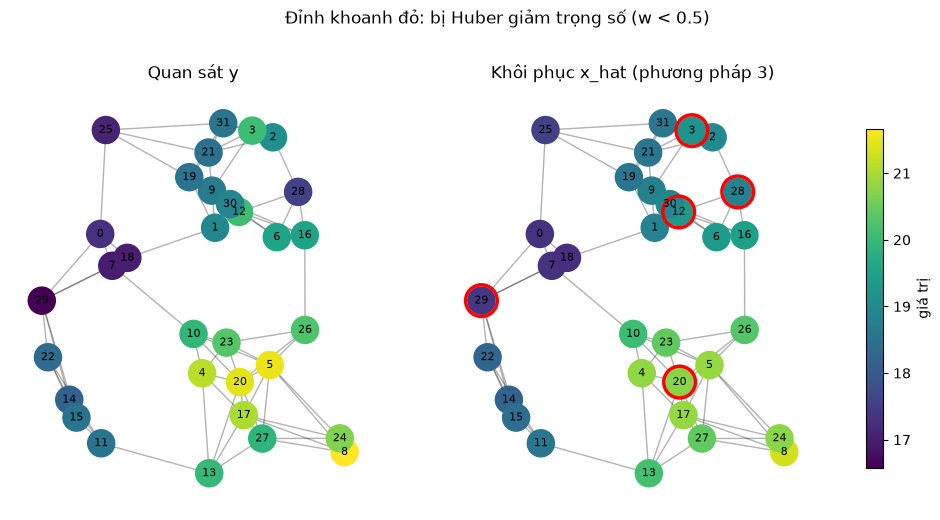

In [7]:
# ---- Hình: y và x_hat trên đồ thị; khoanh đỏ đỉnh bị giảm trọng số mạnh ----
vmin = min(y.min(), x_hat_real.min())
vmax = max(y.max(), x_hat_real.max())
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, vals, title in [(axes[0], y, "Quan sát y"),
                        (axes[1], x_hat_real, "Khôi phục x_hat (phương pháp 3)")]:
    nodes = nx.draw_networkx_nodes(G, positions, node_color=vals, cmap="viridis",
                                   vmin=vmin, vmax=vmax, node_size=380, ax=ax)
    nx.draw_networkx_edges(G, positions, alpha=0.3, ax=ax)
    nx.draw_networkx_labels(G, positions, font_size=8, ax=ax)
    ax.set_title(title)
    ax.axis("off")

suspect = np.flatnonzero(info_real["weights"] < 0.5)
nx.draw_networkx_nodes(G, positions, nodelist=list(suspect), node_color="none",
                       edgecolors="red", linewidths=2.5, node_size=520, ax=axes[1])
fig.colorbar(nodes, ax=axes, label="giá trị", shrink=0.8)
fig.suptitle("Đỉnh khoanh đỏ: bị Huber giảm trọng số (w < 0.5)", y=1.02)
plt.savefig(FIG_DIR / "fig_y_vs_xhat_method3.png", dpi=150, bbox_inches="tight")
plt.show()

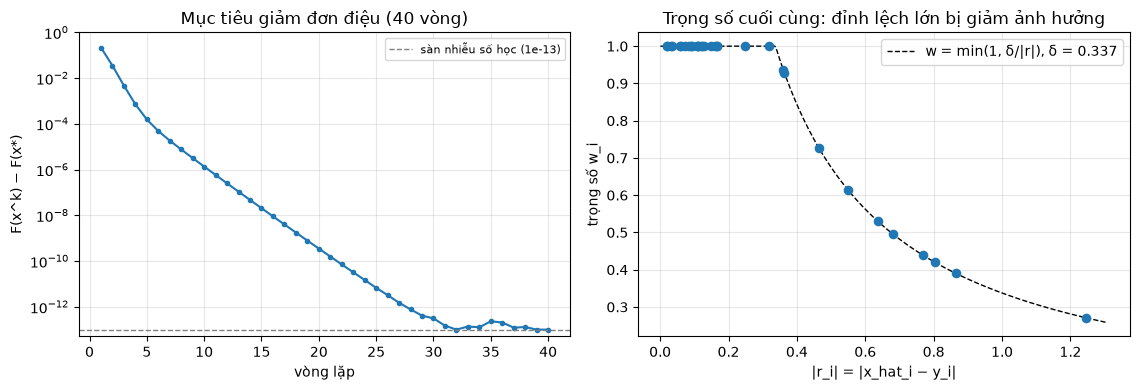

In [8]:
# ---- Hình: quá trình hội tụ của IRLS trên dữ liệu thật ---------------------
obj = np.array(info_real["objective"])
gap = obj - obj[-1]
floor = 1e-13                         # dưới mức này chênh lệch chỉ là nhiễu làm tròn số

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].semilogy(np.arange(1, len(gap) + 1), np.maximum(gap, floor), "o-", ms=3)
axes[0].axhline(floor, color="gray", ls="--", lw=1, label="sàn nhiễu số học (1e-13)")
axes[0].set_ylim(floor / 2, 1)
axes[0].set_xlabel("vòng lặp")
axes[0].set_ylabel("F(x^k) − F(x*)")
axes[0].set_title("Mục tiêu giảm đơn điệu (%d vòng)" % len(obj))
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Trọng số cuối cùng so với độ lớn phần dư: đúng quy tắc w = min(1, delta/|r|).
r_abs = np.abs(x_hat_real - y)
axes[1].scatter(r_abs, info_real["weights"], s=35, zorder=3)
rr = np.linspace(1e-3, r_abs.max() * 1.05, 400)
axes[1].plot(rr, np.minimum(1.0, FINAL_PARAMS["delta"] / rr), "k--", lw=1,
             label="w = min(1, δ/|r|), δ = %.3f" % FINAL_PARAMS["delta"])
axes[1].set_xlabel("|r_i| = |x_hat_i − y_i|")
axes[1].set_ylabel("trọng số w_i")
axes[1].set_title("Trọng số cuối cùng: đỉnh lệch lớn bị giảm ảnh hưởng")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.savefig(FIG_DIR / "fig_convergence_method3.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Dòng kết quả cho bảng so sánh của nhóm

Mỗi phương pháp một dòng, theo quy ước của nhóm: tên phương pháp, tham số tốt nhất, RMSE giả lập
(trung bình ± độ lệch chuẩn trên seed 0–19), `cv_score` trên dữ liệu thật. Cách tính và cách đọc hai con số
này: Phụ lục A (cv_score) và Phụ lục B (dữ liệu giả lập).

In [9]:
synth_final = synth_rmse(FINAL_PARAMS)
result_row = {
    "method": "3. Huber + Laplacian (IRLS)",
    "params": {"alpha": ALPHA, "delta": round(float(FINAL_PARAMS["delta"]), 4), "lam": LAM},
    "synthetic_RMSE_mean": round(float(synth_final.mean()), 4),
    "synthetic_RMSE_std": round(float(synth_final.std()), 4),
    "cv_score": round(float(cv_mean(FINAL_PARAMS)), 4),
}
print(result_row)

# Đối chứng Tikhonov (phương pháp 1) với CÙNG lam, để thấy riêng phần Huber đóng góp gì.
synth_l2 = synth_rmse({"delta": np.inf, "lam": LAM})
print("\nĐối chứng Tikhonov cùng lam = %.2f:" % LAM)
print("  cv_score (5 cách chia) = %.4f | cv_score (20 cách chia) = %.4f"
      % (cv_mean({"delta": np.inf, "lam": LAM}), cv_mean20({"delta": np.inf, "lam": LAM})))
print("  RMSE giả lập = %.4f ± %.4f" % (synth_l2.mean(), synth_l2.std()))
print("\ncv_score của phương pháp 3 (5 cách chia, dùng trong bảng nhóm) = %.4f"
      % cv_mean(FINAL_PARAMS))
print("Lưu ý: Phụ lục A chọn tham số bằng cv trung bình 20 cách chia; dòng kết quả báo cáo theo quy ước 5 cách chia.")

{'method': '3. Huber + Laplacian (IRLS)', 'params': {'alpha': 0.5, 'delta': 0.3374, 'lam': 0.1}, 'synthetic_RMSE_mean': 0.2626, 'synthetic_RMSE_std': 0.0872, 'cv_score': 0.3309}

Đối chứng Tikhonov cùng lam = 0.10:
  cv_score (5 cách chia) = 0.3746 | cv_score (20 cách chia) = 0.4043
  RMSE giả lập = 0.2385 ± 0.0442

cv_score của phương pháp 3 (5 cách chia, dùng trong bảng nhóm) = 0.3309
Lưu ý: Phụ lục A chọn tham số bằng cv trung bình 20 cách chia; dòng kết quả báo cáo theo quy ước 5 cách chia.


## 5. Thuyết minh (Mục VI)

**1. Giả thiết về tín hiệu, nhiễu và các đỉnh gần nhau.**
Tín hiệu thật `x` trơn trên đồ thị: hai cảm biến gần nhau (trọng số `w_ij` lớn) đo những giá trị gần nhau, nên
`xᵀLx = Σ w_ij(x_i−x_j)²` nhỏ. Quan sát `y = x + ε + o`, với `ε` là nhiễu nhỏ ở mọi đỉnh (chủ yếu Gauss) và `o`
là sai số lớn ở một vài đỉnh (outlier), thưa và thường không nằm cạnh nhau. Trọng số cạnh là độ tương tự giữa
cảm biến. Khác giả thiết của phương pháp 1, ở đây nhiễu có **đuôi nặng**: chỉ cần một đỉnh đọc sai lớn là bình
phương tối thiểu bị kéo lệch, nên phần khớp dữ liệu phải bền vững. Hệ quả: `x` là ẩn cần tìm, `y` chỉ vào bài
toán qua hiệu `x−y`; đơn vị của `y` chỉ ảnh hưởng tới cách đặt `δ`.

**2. Hàm mục tiêu.**
`min_x F(x) = Σ_i ρ_δ(x_i−y_i) + λxᵀLx`, với `ρ_δ(r) = ½r²` nếu `|r| ≤ δ` và `δ|r| − ½δ²` nếu `|r| > δ`.
Số hạng đầu đo độ khớp dữ liệu: bậc hai khi phần dư nhỏ (tận dụng giả thiết nhiễu Gauss), tuyến tính khi phần
dư lớn, với đạo hàm `ψ_δ(r) = min(|r|,δ)·sign(r)` bị chặn ở `δ`. Vì thế một outlier chỉ kéo nghiệm với lực tối
đa `δ`, không phải tỉ lệ với độ lệch như L2. Số hạng sau `λxᵀLx` đo độ "gồ ghề" và làm trơn tín hiệu; `λ > 0`
còn bảo đảm nghiệm duy nhất. Ví dụ định lượng: với `δ = 1`, phần dư `r = 5` bị L2 phạt 12.5 (đạo hàm 5), L1
phạt 5 (đạo hàm 1), Huber phạt 4.5 (đạo hàm 1). Hai trường hợp giới hạn: `δ → ∞` cho đúng bài toán Tikhonov
của phương pháp 1; `δ → 0` (với λ phù hợp) tiến tới L1/LAD của phương pháp 4 — phương pháp 3 là trung gian và
`δ` quyết định gần bên nào.

**3. Phương pháp tối ưu và lựa chọn tham số.**
Điều kiện tối ưu là `ψ_δ(r_i) + 2λ(Lx)_i = 0` với `r_i = x_i − y_i`. Đặt `w_i = min(1, δ/|r_i|)` thì
`ψ_δ(r_i) = w_i r_i`, nên điều kiện thành `W(x−y) + 2λLx = 0`, tức `(W + 2λL)x = Wy`. Ma trận `W` phụ thuộc
nghiệm, vì vậy giải lặp (IRLS): `x⁰ = y`; mỗi vòng tính `w_i` từ `x^k` rồi giải `(W^k + 2λL)x^{k+1} = W^k y`.
Mỗi vòng là một bài toán Tikhonov có trọng số; `W^k + 2λL` đối xứng, dương xác định (vì `L` nửa xác định dương
và có ít nhất một `w_i > 0`), nên nghiệm duy nhất và giải bằng một phép phân rã. Mỗi vòng còn là một bước
majorize–minimize nên `F(x^k)` không tăng; `F` lồi và có nghiệm duy nhất, do đó dãy hội tụ. Trên dữ liệu thật:
40 vòng, `F` giảm đơn điệu từ 4.1572 xuống 3.9417, chuẩn KKT `max|g| = 6.8×10⁻⁹`; so với bộ giải lồi L-BFGS
trên cùng hàm mục tiêu, mục tiêu lệch `8×10⁻¹²` (Phụ lục D). Điều kiện dừng: `‖Δx‖/(1+‖x‖) < 10⁻¹⁰`.
Tham số được chọn như sau: `δ = α·s0` với `s0 = 1.4826·MAD(y_i − trung bình láng giềng) = 0.675` (thang nhiễu);
lưới `α ∈ {0.25, …, 2}`, `λ ∈ {0.025, …, 0.25}`, `cv_score` trung bình 20 cách chia; trong các điểm có
`cv_score` trong 3% tốt nhất, chọn điểm có RMSE giả lập thấp nhất. Kết quả: `α = 0.5`, `λ = 0.1`, tức
`δ = 0.337`; `cv_score` = 0.3745 (20 cách chia) và 0.3309 (5 cách chia). Không dùng hằng số cổ điển
`δ = 1.345σ` vì nhiễu thật lớn (`σ ≈ 0.6`, ước lượng ở Phụ lục D) còn outlier thật chỉ vừa (khoảng 2–4σ): ngưỡng lớn sẽ gần như bỏ
qua outlier. Ngược lại `α = 0.25` tốt hơn `cv_score` chút ít nhưng RMSE giả lập tệ hơn hẳn (0.42 so với
0.26), nên bị quy tắc loại.

**4. Thực nghiệm, trực quan hoá nghiệm và giới hạn của mô hình.**
Trên dữ liệu thật, phương pháp giảm trọng số 10 đỉnh, trong đó 5 đỉnh giảm mạnh (`w < 0.5`: các đỉnh 3, 12,
20, 28, 29); đỉnh 28 có `y = 17.55` được kéo về `x_hat = 18.80` (`w = 0.27`) — đây cũng là đỉnh mà phương pháp
6 gắn cờ. So với Tikhonov cùng `λ`, `cv_score` giảm từ 0.4043 xuống 0.3745 (20 cách chia; 0.3746 → 0.3309 với
5 cách chia), tức khoảng 7–12%, nên phần bền vững có đóng góp thực chứ không chỉ là trang trí. Trên 100 đồ thị
công khai, khi mỗi đồ thị được chọn `λ` riêng, Huber chỉ nhỉnh hơn Tikhonov rất nhẹ (`cv_score` trung bình
0.6046 so với 0.6080, thắng 43/100) — lợi ích phụ thuộc mức outlier của từng bộ dữ liệu, không phải lúc nào
cũng lớn. Giới hạn: (a) `δ`, `λ` phụ thuộc thang đo và mức nhiễu, đổi bộ đề phải chọn lại; (b) Huber chỉ giảm
trọng số chứ không loại hẳn outlier như phương pháp 6, nên outlier cực lớn vẫn còn ảnh hưởng; (c) `δ` quá nhỏ
thì gần L1 và mất hiệu quả với nhiễu Gauss, `δ` quá lớn thì quay về Tikhonov; (d) `λ` lớn làm giảm biên độ tín
hiệu (bias), còn `cv_score` chỉ đo các đỉnh bị che nên có thể chọn `λ` hơi lớn so với mục tiêu RMSE; (e) giả
thiết trơn có thể sai ở biên giữa hai vùng; (f) generator giả lập của nhóm có nhiễu nhỏ hơn dữ liệu thật vài
lần, nên RMSE giả lập không dự báo trực tiếp RMSE thật — trên generator này Huber kém Tikhonov cùng `λ` khoảng 0.024 RMSE, nhưng khi hạ `δ` và `λ` cho khớp nhiễu giả lập thì Huber lại nhỉnh hơn (0.233 so với 0.235); (g) mỗi vòng IRLS giải một hệ `n×n` đặc — ổn với 32
đỉnh, nhưng đồ thị lớn cần phân rã thưa.

---
# Phụ lục (đọc thêm)

- **Phụ lục A**: lưới `α` × `λ` trên dữ liệu thật và quy tắc chọn tham số.
- **Phụ lục B**: dữ liệu giả lập có `x` biết trước (seed 0 và seed 0–19).
- **Phụ lục C**: so sánh với Tikhonov trên 100 đồ thị công khai.
- **Phụ lục D**: kiểm tra hội tụ/KKT, so với bộ giải lồi, và chẩn đoán mức nhiễu.

## Phụ lục A. Chọn tham số bằng `cv_score` (dữ liệu thật)

`cv_score` (khối code chung): 5 fold; che 1/5 số đỉnh, chạy toàn bộ phương pháp trên 4/5 còn lại (kể cả bước
tính trọng số), đo `|x_hat − y|` trên các đỉnh bị che, lấy trung vị trên toàn bộ. `cv_score` so với `y` có
nhiễu (không phải `x` thật) và rất nhiễu trên 32 đỉnh, nên ở đây lấy trung bình **20 cách chia** khi cần so
sánh các tham số gần nhau; dòng kết quả ở mục 4 vẫn báo cáo theo quy ước **5 cách chia** của nhóm.

Lưới: `α ∈ {0.25, 0.4, 0.5, 0.75, 1, 1.5, 2}` (tức `δ = α·s0`), `λ ∈ {0.025, 0.05, 0.075, 0.1, 0.15, 0.25}`.
Với mỗi điểm, cell dưới tính `cv_score` (20 cách chia) và RMSE giả lập (20 seed), rồi áp quy tắc: trong các
điểm có `cv_score` trong 3% tốt nhất, chọn RMSE giả lập thấp nhất.

In [10]:
ALPHAS = [0.25, 0.4, 0.5, 0.75, 1.0, 1.5, 2.0]
LAMS = [0.025, 0.05, 0.075, 0.1, 0.15, 0.25]
CV_SEEDS = range(20)

print("Đang tính lưới %d điểm (%d cách chia x 5 fold cho cv)..." % (len(ALPHAS) * len(LAMS), len(CV_SEEDS)))
grid = []
for a in ALPHAS:
    for l in LAMS:
        p = {"delta": a * S0, "lam": l}
        grid.append({"alpha": a, "lam": l,
                     "cv": float(cv_mean20(p, seeds=CV_SEEDS)),
                     "synth": float(synth_rmse(p).mean())})

print("\ncv_score (trung bình 20 cách chia) — hàng alpha, cột lam")
print("alpha\\lam" + "".join("%9g" % l for l in LAMS))
for a in ALPHAS:
    print("%9.2f" % a + "".join("%9.4f" % [g for g in grid if g["alpha"] == a and g["lam"] == l][0]["cv"]
                                for l in LAMS))

best = min(grid, key=lambda g: g["cv"])
TOL_REL = 0.03
candidates = [g for g in grid if g["cv"] <= best["cv"] * (1 + TOL_REL)]
pick = min(candidates, key=lambda g: g["synth"])

print("\ncv_score tốt nhất trên lưới: alpha = %.2f, lam = %.3f -> %.4f (synth %.4f)"
      % (best["alpha"], best["lam"], best["cv"], best["synth"]))
print("ngưỡng 3%%: cv <= %.4f -> %d điểm ứng viên" % (best["cv"] * (1 + TOL_REL), len(candidates)))
print("chọn theo RMSE giả lập thấp nhất: alpha = %.2f, lam = %.3f -> cv %.4f, synth %.4f"
      % (pick["alpha"], pick["lam"], pick["cv"], pick["synth"]))
print("(điểm có cv tốt nhất: alpha = %.2f, lam = %.3f, synth %.4f)"
      % (best["alpha"], best["lam"], best["synth"]))

assert (pick["alpha"], pick["lam"]) == (ALPHA, LAM), "quy tắc phải tái tạo đúng tham số đã dùng ở mục 3"
print("\nQuy tắc tái tạo đúng FINAL_PARAMS (alpha=%.2f, lam=%.2f): OK" % (ALPHA, LAM))

Đang tính lưới 42 điểm (20 cách chia x 5 fold cho cv)...



cv_score (trung bình 20 cách chia) — hàng alpha, cột lam
alpha\lam    0.025     0.05    0.075      0.1     0.15     0.25
     0.25   0.4306   0.3796   0.3706   0.3644   0.4031   0.4466
     0.40   0.4447   0.4118   0.3804   0.3741   0.3705   0.4166
     0.50   0.4437   0.4288   0.3945   0.3745   0.3737   0.3858
     0.75   0.4437   0.4298   0.4165   0.4055   0.3753   0.3745
     1.00   0.4437   0.4298   0.4150   0.4045   0.3793   0.3732
     1.50   0.4437   0.4298   0.4150   0.4043   0.3811   0.3801
     2.00   0.4437   0.4298   0.4150   0.4043   0.3811   0.3800

cv_score tốt nhất trên lưới: alpha = 0.25, lam = 0.100 -> 0.3644 (synth 0.4214)
ngưỡng 3%: cv <= 0.3753 -> 9 điểm ứng viên
chọn theo RMSE giả lập thấp nhất: alpha = 0.50, lam = 0.100 -> cv 0.3745, synth 0.2626
(điểm có cv tốt nhất: alpha = 0.25, lam = 0.100, synth 0.4214)

Quy tắc tái tạo đúng FINAL_PARAMS (alpha=0.50, lam=0.10): OK


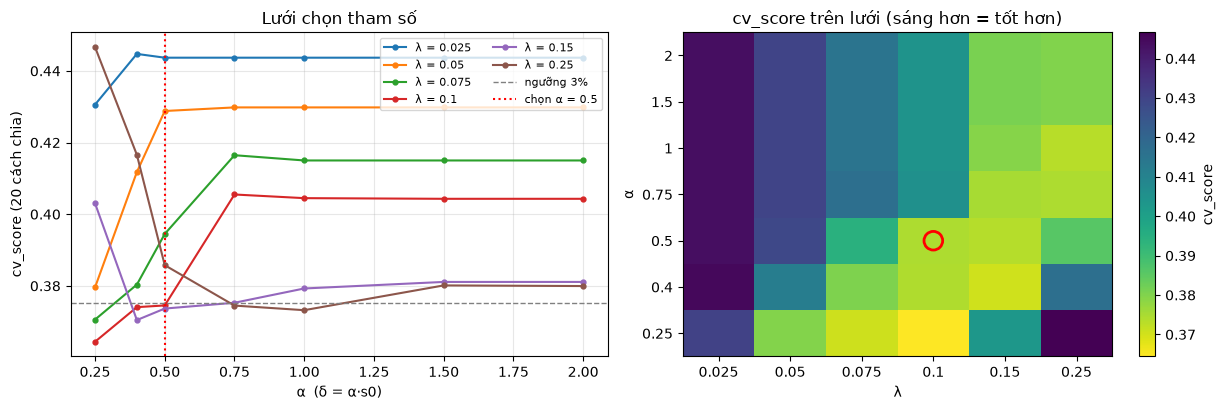

In [11]:
# ---- Hình: đường cong chọn tham số -----------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

for l in LAMS:
    ys = [g["cv"] for g in grid if g["lam"] == l]
    axes[0].plot(ALPHAS, ys, "o-", ms=3.5, label="λ = %g" % l)
axes[0].axhline(best["cv"] * (1 + TOL_REL), color="gray", ls="--", lw=1, label="ngưỡng 3%")
axes[0].axvline(ALPHA, color="red", ls=":", label="chọn α = %.1f" % ALPHA)
axes[0].set_xlabel("α  (δ = α·s0)")
axes[0].set_ylabel("cv_score (20 cách chia)")
axes[0].set_title("Lưới chọn tham số")
axes[0].legend(fontsize=8, ncol=2)
axes[0].grid(alpha=0.3)

M = np.array([[g["cv"] for g in grid if g["alpha"] == a] for a in ALPHAS])
im = axes[1].imshow(M, aspect="auto", origin="lower", cmap="viridis_r")
axes[1].set_xticks(range(len(LAMS)), ["%g" % l for l in LAMS])
axes[1].set_yticks(range(len(ALPHAS)), ["%g" % a for a in ALPHAS])
axes[1].set_xlabel("λ")
axes[1].set_ylabel("α")
axes[1].set_title("cv_score trên lưới (sáng hơn = tốt hơn)")
ia, il = ALPHAS.index(ALPHA), LAMS.index(LAM)
axes[1].scatter([il], [ia], s=180, facecolors="none", edgecolors="red", linewidths=2)
fig.colorbar(im, ax=axes[1], label="cv_score")

fig.tight_layout()
plt.savefig(FIG_DIR / "fig_cv_delta_method3.png", dpi=150, bbox_inches="tight")
plt.show()

## Phụ lục B. Dữ liệu giả lập (biết `x` thật)

`make_synthetic` (khối code chung) tạo `x` trơn trên đúng đồ thị của nhóm, thêm nhiễu Gauss (`σ = 0.1·std(y)`)
và 3 outlier, nên đo được RMSE so với `x` thật. Đây là giả thiết của generator, không nhất thiết đúng với dữ
liệu thật.

### B.1. Kiểm tra một seed: Huber có "nhận ra" các outlier được cài không?

In [12]:
x_true, y_syn = make_synthetic(G, y, seed=0)
x_syn_hat, info_syn = solve_huber(G, y_syn, return_info=True, **FINAL_PARAMS)

planted = np.argsort(-np.abs(y_syn - x_true))[:3]       # 3 đỉnh lệch khỏi x nhiều nhất = outlier được cài
print("outlier được cài (lệch |y−x| lớn nhất):", sorted(planted.tolist()))
print("đỉnh bị giảm trọng số mạnh (w < 0.5):    ", np.flatnonzero(info_syn["weights"] < 0.5).tolist())
print("\nchi tiết các đỉnh được cài:")
for i in planted:
    print("  đỉnh %2d: |y−x| = %5.2f | y = %6.3f | x_hat = %6.3f | w = %.2f"
          % (i, abs(y_syn[i] - x_true[i]), y_syn[i], x_syn_hat[i], info_syn["weights"][i]))
print("\nRMSE của y (không xử lý)      : %.4f" % rmse(y_syn, x_true))
print("RMSE của x_hat (phương pháp 3): %.4f" % rmse(x_syn_hat, x_true))

outlier được cài (lệch |y−x| lớn nhất): [2, 21, 27]
đỉnh bị giảm trọng số mạnh (w < 0.5):     [2]

chi tiết các đỉnh được cài:
  đỉnh  2: |y−x| =  0.89 | y = 21.049 | x_hat = 20.120 | w = 0.36
  đỉnh 27: |y−x| =  0.87 | y = 19.061 | x_hat = 18.586 | w = 0.71
  đỉnh 21: |y−x| =  0.85 | y = 19.401 | x_hat = 19.644 | w = 1.00

RMSE của y (không xử lý)      : 0.2885
RMSE của x_hat (phương pháp 3): 0.2057


### B.2. RMSE trên seed 0–19

Đối chứng: `x_hat = y` (không xử lý), Tikhonov cùng `λ`, và phương pháp 6 (dùng làm mốc so sánh của nhóm).

In [13]:
# RMSE giả lập cho 4 phương án, cùng 20 seed.
base = np.array([rmse(make_synthetic(G, y, sd)[1], make_synthetic(G, y, sd)[0]) for sd in range(20)])
r_huber = synth_rmse(FINAL_PARAMS)
r_l2 = synth_rmse({"delta": np.inf, "lam": LAM})

import sys
sys.path.append(str(ROOT / "src" / "method_6"))
from method6_outliers import solve_two_stage
r_m6 = np.array([rmse(solve_two_stage(G, make_synthetic(G, y, sd)[1]), make_synthetic(G, y, sd)[0])
                 for sd in range(20)])

print("%-38s %s" % ("phương án", "RMSE giả lập (20 seed)"))
print("%-38s %.4f ± %.4f" % ("x_hat = y (không xử lý)", base.mean(), base.std()))
print("%-38s %.4f ± %.4f" % ("Huber (δ = %.3f, λ = %.1f)" % (FINAL_PARAMS["delta"], LAM),
                            r_huber.mean(), r_huber.std()))
print("%-38s %.4f ± %.4f" % ("Tikhonov cùng λ = %.1f" % LAM, r_l2.mean(), r_l2.std()))
print("%-38s %.4f ± %.4f" % ("Phương pháp 6 (hai giai đoạn)", r_m6.mean(), r_m6.std()))

diff = r_huber - r_l2
print("\nHuber − Tikhonov (ghép từng seed): %+.4f ± %.4f (sai số chuẩn %.4f)"
      % (diff.mean(), diff.std(), diff.std() / np.sqrt(len(diff))))
print("=> trên generator của nhóm, Huber kém hơn khoảng %.3f RMSE; xem thảo luận ở mục 5." % diff.mean())

# Nếu đưa delta về gần thang nhiễu của generator (alpha = 0.3) và giảm lam:
r_small = synth_rmse({"delta": 0.3 * S0, "lam": 0.05})
r_l2_small = synth_rmse({"delta": np.inf, "lam": 0.05})
print("\nVới delta khớp nhiễu giả lập hơn (alpha = 0.3) và lam = 0.05:")
print("  Huber = %.4f ± %.4f | Tikhonov = %.4f ± %.4f"
      % (r_small.mean(), r_small.std(), r_l2_small.mean(), r_l2_small.std()))
print("  => khi delta khớp thang nhiễu, Huber lại nhỉnh hơn Tikhonov trên generator này.")

phương án                              RMSE giả lập (20 seed)
x_hat = y (không xử lý)                0.2928 ± 0.0317
Huber (δ = 0.337, λ = 0.1)             0.2626 ± 0.0872
Tikhonov cùng λ = 0.1                  0.2385 ± 0.0442
Phương pháp 6 (hai giai đoạn)          0.2465 ± 0.0583

Huber − Tikhonov (ghép từng seed): +0.0241 ± 0.0494 (sai số chuẩn 0.0111)
=> trên generator của nhóm, Huber kém hơn khoảng 0.024 RMSE; xem thảo luận ở mục 5.



Với delta khớp nhiễu giả lập hơn (alpha = 0.3) và lam = 0.05:
  Huber = 0.2326 ± 0.0583 | Tikhonov = 0.2351 ± 0.0312
  => khi delta khớp thang nhiễu, Huber lại nhỉnh hơn Tikhonov trên generator này.


## Phụ lục C. So sánh với Tikhonov trên 100 đồ thị công khai

Câu hỏi: phần Huber có lợi ích **tổng quát** hay chỉ tốt cho bộ dữ liệu của nhóm? Với mỗi đồ thị trong
`public_cases.json`, chọn `λ ∈ {0.05, 0.1, 0.2}` riêng cho từng phương pháp bằng `cv_score` (3 cách chia cho
nhanh), giữ `α = 0.5` cho Huber (với `s0` tính trên chính đồ thị đó), rồi so sánh. Đây là phép so sánh công
bằng hơn dùng chung một `λ`, vì mỗi đồ thị có mức nhiễu khác nhau.

In [14]:
ALL = json.loads((ROOT / "public_cases.json").read_text(encoding="utf-8"))["cases"]

def load_case(cid):
    c = ALL[cid]
    Gc = nx.Graph()
    for i, xy in enumerate(c["positions"]):
        Gc.add_node(i, pos=tuple(map(float, xy)))
    for u, v, w in c["edges"]:
        Gc.add_edge(int(u), int(v), weight=float(w))
    return Gc, np.asarray(c["y"], dtype=float)

def cv_on(Gc, yc, params, seeds=range(3)):
    # cv_score cho một đồ thị bất kỳ (cùng định nghĩa với khối code chung).
    nn = len(yc)
    out = []
    for sd in seeds:
        folds = np.random.default_rng(sd).permutation(nn) % 5
        err = []
        for f in range(5):
            mk = folds != f
            err.append(np.abs(solve_huber(Gc, yc, mask=mk, **params)[~mk] - yc[~mk]))
        out.append(np.median(np.concatenate(err)))
    return float(np.mean(out))

LAMS_C = [0.05, 0.1, 0.2]
rows_c = []
for cid in sorted(ALL):
    Gc, yc = load_case(cid)
    s0c = noise_scale(Gc, yc)
    c_h = {l: cv_on(Gc, yc, {"delta": 0.5 * s0c, "lam": l}) for l in LAMS_C}
    c_l = {l: cv_on(Gc, yc, {"delta": np.inf, "lam": l}) for l in LAMS_C}
    bh, bl = min(c_h, key=c_h.get), min(c_l, key=c_l.get)
    rows_c.append({"cid": cid, "huber": c_h[bh], "l2": c_l[bl], "lam_h": bh, "lam_l": bl})

h = np.array([r["huber"] for r in rows_c])
l2 = np.array([r["l2"] for r in rows_c])
print("Số đồ thị:", len(rows_c))
print("cv_score trung bình — Huber: %.4f | Tikhonov: %.4f | trung vị: %.4f vs %.4f"
      % (h.mean(), l2.mean(), np.median(h), np.median(l2)))
print("Huber tốt hơn Tikhonov ở %d/%d đồ thị" % (int((h < l2).sum()), len(h)))
print("λ tốt nhất được chọn: Huber", {v: sum(1 for r in rows_c if r["lam_h"] == v) for v in LAMS_C},
      "| Tikhonov", {v: sum(1 for r in rows_c if r["lam_l"] == v) for v in LAMS_C})
print("Chênh lệch trung vị (Huber − Tikhonov): %+.4f" % np.median(h - l2))

Số đồ thị: 100
cv_score trung bình — Huber: 0.6046 | Tikhonov: 0.6080 | trung vị: 0.5912 vs 0.6040
Huber tốt hơn Tikhonov ở 43/100 đồ thị
λ tốt nhất được chọn: Huber {0.05: 45, 0.1: 24, 0.2: 31} | Tikhonov {0.05: 41, 0.1: 18, 0.2: 41}
Chênh lệch trung vị (Huber − Tikhonov): +0.0018


## Phụ lục D. Kiểm tra hội tụ, tính đúng đắn và mức nhiễu

Bốn kiểm tra: (1) IRLS cho cùng nghiệm với bộ giải lồi L-BFGS trên đúng hàm mục tiêu; (2) `δ = ∞` trùng
nghiệm Tikhonov đóng đã kiểm tra ở mục 2; (3) notebook và module `method3_huber.py` cho cùng kết quả;
(4) chẩn đoán mức nhiễu thật từ cấu trúc phổ của `y` (chỉ để giải thích, không dùng để chọn tham số).

In [15]:
import sys

from scipy.optimize import minimize

# (1) So với bộ giải lồi L-BFGS trên cùng F(x).
f = lambda z: huber_objective(G, y, z, FINAL_PARAMS["delta"], LAM)
res = minimize(f, y, method="L-BFGS-B", options={"maxiter": 50000, "ftol": 1e-16, "gtol": 1e-12})
print("F(x_hat) = %.10f | L-BFGS = %.10f | chênh lệch = %.2e"
      % (f(x_hat_real), res.fun, abs(f(x_hat_real) - res.fun)))
print("max|IRLS − L-BFGS| = %.2e  (L-BFGS dừng theo gtol nên khác ở mức 1e-6)"
      % np.max(np.abs(x_hat_real - res.x)))

# (2) Notebook và module dùng chung phải cho cùng kết quả.
sys.path.append(str(ROOT / "src" / "method_3"))
from method3_huber import solve_huber as solve_huber_module
assert np.allclose(solve_huber_module(G, y, **FINAL_PARAMS), x_hat_real, atol=1e-12)
print("notebook == module src/method_3/method3_huber.py: OK")

# (3) Chẩn đoán mức nhiễu: phần ngoài 5 mode thấp nhất của y.
ev, U = np.linalg.eigh(L)
coef = U.T @ y
share = (coef[:5] ** 2).sum() / (coef ** 2).sum()
print("\nNăng lượng của y trong 5 mode thấp nhất: %.2f%%" % (100 * share))
print("Độ lệch chuẩn phần ngoài 5 mode (nếu x thật chỉ gồm 5 mode): %.3f"
      % np.sqrt(np.mean(coef[5:] ** 2)))
print("σ của generator giả lập = 0.1·std(y) = %.3f" % (0.1 * np.std(y)))
print("=> dữ liệu thật nhiễu hơn generator của nhóm, nên RMSE giả lập không dự báo trực tiếp RMSE thật.")

F(x_hat) = 3.9417376670 | L-BFGS = 3.9417376670 | chênh lệch = 8.37e-12
max|IRLS − L-BFGS| = 1.68e-06  (L-BFGS dừng theo gtol nên khác ở mức 1e-6)
notebook == module src/method_3/method3_huber.py: OK

Năng lượng của y trong 5 mode thấp nhất: 99.91%
Độ lệch chuẩn phần ngoài 5 mode (nếu x thật chỉ gồm 5 mode): 0.646
σ của generator giả lập = 0.1·std(y) = 0.141
=> dữ liệu thật nhiễu hơn generator của nhóm, nên RMSE giả lập không dự báo trực tiếp RMSE thật.
